# Global land cover from coordinates

Train a [Wrap encoder](https://github.com/MarcCoru/locationencoder/blob/main/locationencoder/pe/wrap.py) and MLP to predict the [CGLC-MODIS-LCZ map](https://zenodo.org/records/7670653) from longitude and latitude.
Then fit a linear classifier on the bottleneck embeddings and plot their first three PCA components as RGB.

Each pixel has one class, so we use cross-entropy.
Included class IDs are 1–16, 18–21, and 51–61, remapped to 0–30 for training.
We include lakes (21) and exclude ocean (17), unclassified, and unused IDs.
Training samples the full map, with its length set in batches.

## Setup

`input_dim` and `output_dim` are the equal feature widths on either side of the MLP bottleneck. `hidden_dim` is the smaller middle layer and the number of saved embedding bands. `num_classes` sets the separate linear classifier.

The default is `Wrap (4) → projection (256) → bottleneck (128) → expansion (256) → class logits (31)`. ReLU follows the projection, bottleneck, and expansion.

`nearby_fraction = 0.5` mixes equal numbers of random anchors and nearby pixels; set it to 0 to disable nearby sampling.
Each I/O thread reads one random tile per batch, and the loader prefetches the next batch.
`batch_size` must be divisible by `io_workers`.

In [1]:
from concurrent.futures import ThreadPoolExecutor
from contextlib import ExitStack
from pathlib import Path

import lightning as L
import numpy as np
import rasterio
import torch
from huggingface_hub import hf_hub_download
from lightning.pytorch.loggers import CSVLogger
from rasterio.windows import Window
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, IterableDataset

source = Path("data/CGLC-MODIS-LCZ-100m.cog.tif")
output = Path("outputs")
input_dim = 256
hidden_dim = 128
output_dim = input_dim
class_codes = np.r_[1:17, 18:22, 51:62].astype("uint8")
num_classes = len(class_codes)
batch_size = 4096
io_workers = 8
train_steps = 5000
probe_steps = 1000
test_batches = 16
eval_every = 250
learning_rate = 1e-3
nearby_fraction = 0.5
radius_pixels = 5
preview_height = 256
seed = 0
source.parent.mkdir(exist_ok=True)
output.mkdir(exist_ok=True)
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(seed)
torch.set_num_threads(4)
torch.set_float32_matmul_precision("high")
assert batch_size % io_workers == 0 and 0 <= nearby_fraction <= 1
assert 3 <= hidden_dim < input_dim == output_dim and radius_pixels >= 0
print(device)
from plot import plot_cog, plot_comparison, plot_metrics, read_palette

mps


## Download and explore

Download the full COG, then drag and zoom through it with [Development Seed’s Lonboard](https://developmentseed.org/lonboard/latest/examples/raster-cog-nlcd-server/). Async-GeoTIFF reads the internal tiles and overviews on demand through the notebook kernel. No tile server or port forwarding is needed. Ocean and excluded classes are transparent.

Keep the kernel running to explore the map. The static comparison below remains visible without running the notebook. The source grid is nominally 100 m in EPSG:4326; ground spacing varies with latitude.


In [2]:
source = Path(
    hf_hub_download(
        repo_id="taylor-geospatial/neural-earth-fields-hackathon",
        repo_type="dataset",
        filename="CGLC-MODIS-LCZ-100m.cog.tif",
        local_dir="data",
        token=False,
    )
)
with rasterio.open(source) as src:
    assert src.count == 1 and src.crs.to_epsg() == 4326
    width, height = src.width, src.height
    affine = src.transform
    tile_size = src.block_shapes[0][0]
    print(f"{width:,} × {height:,} pixels; {src.res}; {src.block_shapes[0]} tiles")
lookup = np.full(256, -1, dtype=np.int64)
lookup[class_codes] = np.arange(num_classes)

palette_path = hf_hub_download(
    repo_id="taylor-geospatial/neural-earth-fields-hackathon",
    repo_type="dataset",
    filename="cmap_Qgis_CGLC_MOD_LCZ.txt",
    local_dir="data",
    token=False,
)
colors = read_palette(palette_path, class_codes)
land_cover_map = await plot_cog(source, colors)
land_cover_map

400,752 × 153,622 pixels; (0.0008983152841194946, 0.0008983152841194824); (512, 512) tiles


## Pixel batches

A pixel hash assigns about 20% of pixels to the test split.
Training excludes these pixels, including when sampling neighbors.
We reuse fixed test batches to plot the loss.

Each reader picks a random tile and samples land and lake pixels within it.
Tiles without included classes are skipped. Ocean pixels never enter either split.
Nearby samples fall within ±`radius_pixels` rows and columns of an anchor.
Invalid candidates fall back to the anchor, so duplicates are possible.
Neighbors can share a class; they are not necessarily hard negatives.
Sampling is uniform within each selected tile's valid pixels.

In [3]:
def held_out(rows, cols):
    return (
        (rows.astype(np.int64) * 73856093) ^ (cols.astype(np.int64) * 19349663)
    ) % 5 == 0


def lonlat(rows, cols):
    return np.column_stack(
        (affine.c + (cols + 0.5) * affine.a, affine.f + (rows + 0.5) * affine.e)
    ).astype("float32")


def sample_tile(src, seed, test, fraction, count):
    rng = np.random.default_rng(seed)
    while True:
        row = rng.integers((height + tile_size - 1) // tile_size) * tile_size
        col = rng.integers((width + tile_size - 1) // tile_size) * tile_size
        labels = lookup[
            src.read(
                1,
                window=Window(
                    col_off=col, row_off=row, width=tile_size, height=tile_size
                ),
            )
        ]
        rr, cc = np.indices(labels.shape)
        allowed = (labels >= 0) & (held_out(rr + row, cc + col) == test)
        candidates = np.flatnonzero(allowed)
        if len(candidates):
            break
    ids = rng.choice(candidates, count)
    r, c = np.unravel_index(ids, labels.shape)
    n_near = int(count * fraction)
    if n_near:
        dr, dc = rng.integers(-radius_pixels, radius_pixels + 1, (2, n_near))
        nr, nc = r[:n_near] + dr, c[:n_near] + dc
        inside = (nr >= 0) & (nr < labels.shape[0]) & (nc >= 0) & (nc < labels.shape[1])
        nr, nc = nr.clip(0, labels.shape[0] - 1), nc.clip(0, labels.shape[1] - 1)
        keep = inside & allowed[nr, nc]
        r[-n_near:] = np.where(keep, nr, r[:n_near])
        c[-n_near:] = np.where(keep, nc, c[:n_near])
    return lonlat(r + row, c + col), labels[r, c]


class PixelBatches(IterableDataset):
    def __init__(self, steps, test=False, fraction=0, seed=0, size=None):
        self.steps, self.test, self.fraction, self.seed = steps, test, fraction, seed
        self.size = batch_size if size is None else size
        assert self.size % io_workers == 0

    def __iter__(self):
        rng = np.random.default_rng(self.seed)
        with ExitStack() as stack, ThreadPoolExecutor(io_workers) as pool:
            readers = [
                stack.enter_context(rasterio.open(source)) for _ in range(io_workers)
            ]
            pending = []
            for step in range(self.steps + 1):
                parts = [future.result() for future in pending]
                if step < self.steps:
                    pending = [
                        pool.submit(
                            sample_tile,
                            reader,
                            int(rng.integers(2**32)),
                            self.test,
                            self.fraction,
                            self.size // io_workers,
                        )
                        for reader in readers
                    ]
                if parts:
                    yield tuple(
                        torch.from_numpy(np.concatenate(items)) for items in zip(*parts)
                    )


def batches(steps, test=False, fraction=0, seed=0, size=None):
    return DataLoader(
        PixelBatches(steps, test, fraction, seed, size),
        batch_size=None,
        num_workers=0,
        pin_memory=device.type == "cuda",
    )


test_data = list(batches(test_batches, test=True, seed=seed + 1, size=4096))
print(f"{sum(len(y) for _, y in test_data):,} fixed test pixels")

65,536 fixed test pixels


## Wrap + MLP

Wrap converts `[longitude, latitude]` in degrees to `[cos(lon), sin(lon), cos(lat), sin(lat)]`.
Conversion and trigonometric operations run in place; the four-feature output needs one allocation.
Pass fresh tensors, or clone inputs you need to reuse.
Coordinate gradients are not supported.

The model is `nn.Sequential(encoder, decoder, linear_head)`.
`model[0]` returns the middle bottleneck activations after ReLU. The decoder expands them to `output_dim`, then the final linear head produces class logits.

In [4]:
class Wrap(nn.Module):
    def forward(self, coords):
        coords.deg2rad_()
        features = coords.repeat_interleave(2, dim=-1)
        features[:, 0::2].cos_()
        features[:, 1::2].sin_()
        return features


encoder = nn.Sequential(
    Wrap(),
    nn.Linear(4, input_dim),
    nn.ReLU(inplace=True),
    nn.Linear(input_dim, hidden_dim),
    nn.ReLU(inplace=True),
)
decoder = nn.Sequential(nn.Linear(hidden_dim, output_dim), nn.ReLU(inplace=True))
model = nn.Sequential(encoder, decoder, nn.Linear(output_dim, num_classes)).to(device)
criterion = nn.CrossEntropyLoss()
print(model)

Sequential(
  (0): Sequential(
    (0): Wrap()
    (1): Linear(in_features=4, out_features=256, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU(inplace=True)
  )
  (1): Sequential(
    (0): Linear(in_features=128, out_features=256, bias=True)
    (1): ReLU(inplace=True)
  )
  (2): Linear(in_features=256, out_features=31, bias=True)
)


## Training and metrics

Lightning handles optimization, device transfers, validation, and CSV logging.
Track cross-entropy and accuracy during training, plus macro F1 and mean IoU on fixed held-out pixels.
F1 and IoU average over classes present in those labels. This pixel split measures interpolation within the map.
The training curves show logged batches; validation curves use the same full sample each time.


GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.



Training: |          | 0/? [00:00<?, ?it/s]


Training: |          | 0/? [00:00<?, ?it/s]

... (10,422 outputs left out)


Validation DataLoader 0:  94%|█████████▍| 15/16 [00:00<00:00, 309.56it/s]


Validation DataLoader 0: 100%|██████████| 16/16 [00:00<00:00, 311.96it/s]


Validation DataLoader 0: 100%|██████████| 16/16 [00:00<00:00, 240.16it/s]


{'cross_entropy': 1.6064246892929077, 'accuracy': 0.484710693359375, 'macro_f1': 0.2726897895336151, 'miou': 0.19295944273471832}


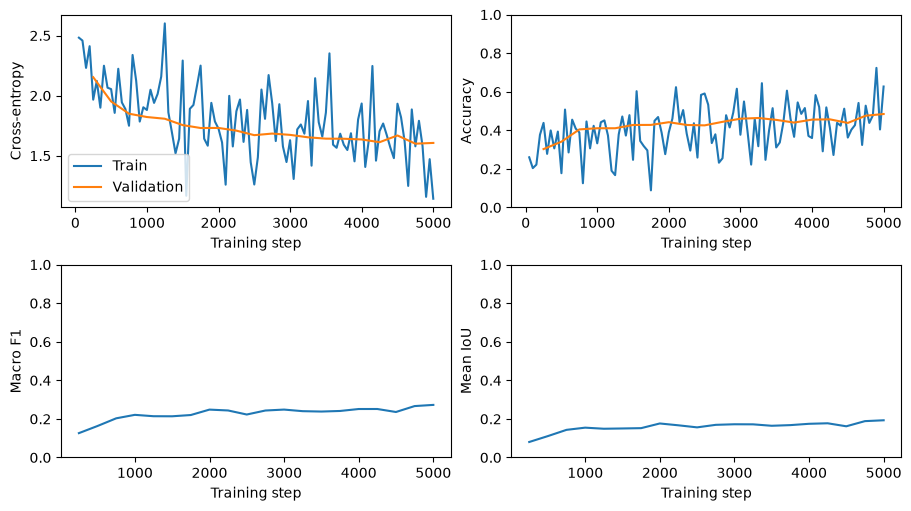

In [5]:
def classification_scores(target, prediction):
    cm = confusion_matrix(target, prediction, labels=np.arange(num_classes))
    tp, support = np.diag(cm), cm.sum(1)
    total = support + cm.sum(0)
    present = support > 0
    return {
        "accuracy": tp.sum() / cm.sum(),
        "macro_f1": (2 * tp / total.clip(1))[present].mean(),
        "miou": (tp / (total - tp).clip(1))[present].mean(),
    }


class LandCoverTask(L.LightningModule):
    def __init__(self, network):
        super().__init__()
        self.network = network
        self.validation_outputs = []

    def training_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords)
        loss = criterion(logits, target)
        self.log_dict(
            {
                "train_loss": loss,
                "train_accuracy": (logits.argmax(1) == target).float().mean(),
            }
        )
        return loss

    def validation_step(self, batch, batch_idx):
        coords, target = batch
        logits = self.network(coords.clone())
        self.log("cross_entropy", criterion(logits, target), batch_size=len(target))
        self.validation_outputs.append((target.cpu(), logits.argmax(1).cpu()))

    def on_validation_epoch_end(self):
        target, prediction = map(torch.cat, zip(*self.validation_outputs))
        self.log_dict(classification_scores(target.numpy(), prediction.numpy()))
        self.validation_outputs.clear()

    def configure_optimizers(self):
        return torch.optim.Adam(
            (p for p in self.parameters() if p.requires_grad), lr=learning_rate
        )


def fit(network, steps, name, fraction=0):
    logger = CSVLogger(output, name=name)
    trainer = L.Trainer(
        accelerator=device.type,
        devices=1,
        max_steps=steps,
        val_check_interval=min(eval_every, steps),
        check_val_every_n_epoch=None,
        log_every_n_steps=min(50, steps),
        num_sanity_val_steps=0,
        enable_checkpointing=False,
        enable_model_summary=False,
        logger=logger,
    )
    task = LandCoverTask(network)
    validation = DataLoader(test_data, batch_size=None)
    trainer.fit(task, batches(steps, fraction=fraction, seed=seed), validation)
    print(trainer.validate(task, validation, verbose=False)[0])
    network.to(device).eval()
    return Path(logger.log_dir) / "metrics.csv"


history = fit(model, train_steps, "wrap_mlp", nearby_fraction)
plot_metrics(history, output / "wrap_mlp_metrics.png")

## Linear probe

Freeze the middle-layer embeddings and fit a separate linear classifier directly on them. The main model predicts through the expansion layer and its own linear head. This probe tests what a linear classifier can recover from the compressed representation alone.

GPU available: True (mps), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/isaaccroley/github/neuralearthfields-starter/.venv/lib/python3.12/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/isaaccroley/github/neuralearthfields-starter/.venv/l


Training: |          | 0/? [00:00<?, ?it/s]


Training: |          | 0/? [00:00<?, ?it/s]

... (2,102 outputs left out)


Validation DataLoader 0:  94%|█████████▍| 15/16 [00:00<00:00, 244.94it/s]


Validation DataLoader 0: 100%|██████████| 16/16 [00:00<00:00, 250.09it/s]


Validation DataLoader 0: 100%|██████████| 16/16 [00:00<00:00, 196.15it/s]

{'cross_entropy': 1.93169105052948, 'accuracy': 0.3795166015625, 'macro_f1': 0.1872696429491043, 'miou': 0.1253916621208191}


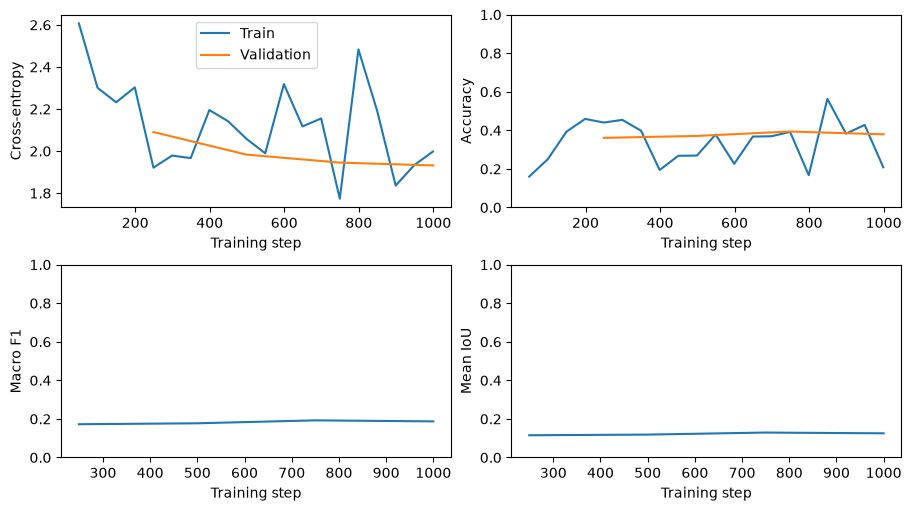

In [6]:
encoder = model[0].eval().requires_grad_(False)
linear_head = nn.Linear(hidden_dim, num_classes).to(device)
probe = nn.Sequential(encoder, linear_head)
probe_history = fit(probe, probe_steps, "linear_head")
plot_metrics(probe_history, output / "linear_head_metrics.png")


@torch.inference_mode()
def predict(network, features):
    return torch.cat(
        [
            network(part.to(device, copy=True)).cpu()
            for part in features.split(batch_size)
        ]
    )


torch.save(
    {
        "model": model.state_dict(),
        "linear_head": linear_head.state_dict(),
        "architecture": "hourglass",
        "input_dim": input_dim,
        "hidden_dim": hidden_dim,
        "output_dim": output_dim,
        "num_classes": num_classes,
        "class_codes": class_codes.tolist(),
    },
    output / "model.pt",
)

## PCA RGB

Fit PCA on the middle bottleneck activations from `model[0]`, before the expansion layer. Use the first three components as RGB.
These are the same `hidden_dim` features written to the embedding COG.
Stretch each component using its 2nd–98th percentiles.
Plot a downsampled view of the full map, with the dataset's colors for land-cover classes.

PCA explained variance: [0.309 0.25  0.162]


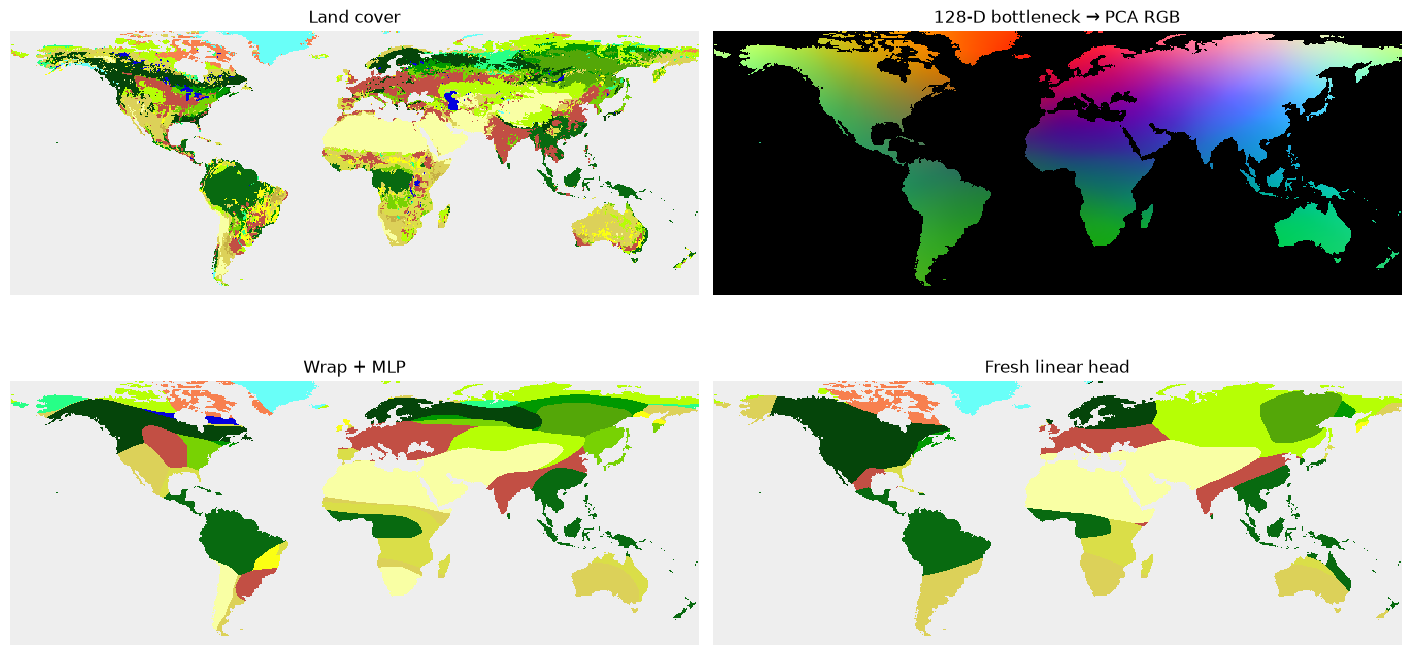

In [6]:
preview_width = round(preview_height * width / height)
with rasterio.open(source) as src:
    overview = src.read(1, out_shape=(preview_height, preview_width))

pca_coords = torch.cat(
    [coords for coords, _ in batches(test_batches, seed=seed + 2, size=4096)]
)
pca_features = predict(encoder, pca_coords).numpy()
pca = PCA(3, random_state=seed).fit(pca_features)
lo, hi = np.percentile(pca.transform(pca_features), [2, 98], axis=0)
rr, cc = np.indices(overview.shape)
rows = np.minimum(
    ((rr.ravel() + 0.5) * height / preview_height).astype(int), height - 1
)
cols = np.minimum(((cc.ravel() + 0.5) * width / preview_width).astype(int), width - 1)
preview_coords = torch.from_numpy(lonlat(rows, cols))
preview_features = predict(encoder, preview_coords)
original_pred = (
    predict(model[1:], preview_features).argmax(1).numpy().reshape(overview.shape)
)
linear_pred = (
    predict(linear_head, preview_features).argmax(1).numpy().reshape(overview.shape)
)
scores = pca.transform(preview_features.numpy())
rgb = np.clip((scores - lo) / np.maximum(hi - lo, 1e-8), 0, 1).reshape(
    *overview.shape, 3
)
print(f"PCA explained variance: {pca.explained_variance_ratio_.round(3)}")

plot_comparison(
    lookup[overview],
    {"Wrap + MLP": original_pred, "Fresh linear head": linear_pred},
    rgb,
    colors,
    class_codes,
    hidden_dim,
    output / "global_comparison.png",
)

## Export rasters

Open [inference.ipynb](inference.ipynb) to load the checkpoint and export float32 middle-layer embeddings and land-cover predictions as COGs.

The source dataset is by Demuzere, He, Martilli, and Zonato (2023), [A hybrid 100-m global land cover dataset with Local Climate Zones for WRF](https://doi.org/10.5281/zenodo.7670653), under CC BY 4.0.